# Cold–warm metric: load data, percentiles & difference plots

**What's in this notebook**

- Loads experiment and reanalysis SST percentile data.
- Plots percentiles and inter-experiment differences.

_Split from `cw_metric.ipynb`. Shared helpers in `functions.py`; outputs stripped — re-run to regenerate figures._


In [1]:
# Load Packages 

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import math
import cartopy.crs as ccrs
import calendar
from matplotlib.lines import Line2D
import os
import re
import seaborn as sns
import pandas as pd
import matplotlib.gridspec as gridspec
from scipy.stats import norm
# from mpl_toolkits.basemap import Basemap
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as patches
from scipy.stats import scoreatpercentile
# import xesmf as xe
from matplotlib.gridspec import GridSpec
import matplotlib

%matplotlib inline


In [2]:
import sys, os
# make this repo's functions.py importable from any subfolder
_p = os.getcwd()
for _ in range(6):
    if os.path.exists(os.path.join(_p, 'functions.py')):
        sys.path.insert(0, _p); break
    _p = os.path.dirname(_p)
from functions import *  # shared helper functions


In [ ]:
# Load variables produced by earlier (compute/loader) notebooks.
# Run those first; harmless if there's nothing saved yet.
load_state(globals())


## load data and find percentiles 

In [3]:
# omip models - so not access-om2 era5 run

# load percentile data processed in gadi 

mod_labs = ['MRI-ESM2-0', 'FGOALS-f3-L','EC-EARTH3','ACCESS-OM2-JRA55-cycle6_iaf'] # ,'ACCESS-OM2-ERA5'

save_directory = '/Users/isabelaconde/Desktop/data/omip/sst_percentiles/'

file_paths = [f"{save_directory}SST_percentile_{model}_1982-2018_gr.nc" for model in mod_labs]

# some datasets have cftime - change in loop below
import datetime
td = datetime.datetime.strptime("1982-01-01", "%Y-%m-%d")
k = 444
d = pd.date_range(td, periods=k, freq='MS')

dict_percentiles_omip = {}

for i, file in enumerate(file_paths):
    dict_percentiles_omip[mod_labs[i]] = xr.open_dataarray(file).assign_coords({'time': d})


# apply function to each model

percentiles_omip_trend = {}
for i, da in enumerate(mod_labs):
    
    percentiles_omip_trend[da]=find_trend_percentile(dict_percentiles_omip[da].sel(time = slice('1982','2017')))
    print('trend calculated for ' + mod_labs[i])

# for i in range(len(mod_labs)):
#     # plot trends of highest and lowest model 
#     percentiles_omip_trend[mod_labs[i]].plot(label = mod_labs[i])  



trend calculated for MRI-ESM2-0
trend calculated for FGOALS-f3-L
trend calculated for EC-EARTH3
trend calculated for ACCESS-OM2-JRA55-cycle6_iaf


In [4]:
cw_mean_omip = {}
for i, da in enumerate(mod_labs):
    
    dt = dict_percentiles_omip[da].sel(time = slice('1982','2017'))
    cw_mean_omip[da]=(dt.sel(area = slice(0.5,1)).mean(dim = 'area') - dt.sel(area = slice(0,0.5)).mean(dim = 'area')).mean(dim = 'time')
    print('cw mean for ' + mod_labs[i])




cw mean for MRI-ESM2-0
cw mean for FGOALS-f3-L
cw mean for EC-EARTH3
cw mean for ACCESS-OM2-JRA55-cycle6_iaf


In [5]:
# cmip modules 
trend_percentile = xr.open_datatree('/Users/isabelaconde/Desktop/data/dt_cmip_percentiles_trend_1982-2018.nc')

# find mods
# Get ensemble names - yes so you can call on it later
models =['CESM1-CAM5',
 'CanESM2',
 'GFDL-ESM2M',
 'MPI-ESM',
 'ACCESS-ESM1-5',
 'CanESM5',
 'EC-Earth3',
 'IPSL-CM6A-LR',
 'MIROC-ES2L',
 'MIROC6',
 'MPI-ESM1-2-LR',
 'CESM2',
 'GFDL-SPEAR-MED']

data_tree=trend_percentile

mods = {}
for model_name, model_data in data_tree.items():
    en=[]
    for ensemble_name, ensemble_data in data_tree[model_name].items():
        en.extend([str(ensemble_name)])
    
    mods[str(model_name)]=en

    
trend_dt=trend_percentile
model_array=[]
da=[]

for m in range(len(models)):
    sources = mods[models[m]][0:len(mods[models[m]])]
    # da=[] # initialise array for grad values
    for i in range(len(sources)):
        da.extend(trend_dt[models[m]].grad.values)

DA_all = xr.DataArray(np.squeeze(da), dims=['run','area'], coords={'run': np.linspace(0, 1, 519), 'area': np.linspace(0, 1, 100)})


# DA_all= xr.open_dataarray('/Users/isabelaconde/Desktop/data/final_data/da_all_cmip56_runs.nc')

def calculate_confidence_intervals_all(data, n):
    mean = np.empty(n)
    lower = np.empty(n)
    upper = np.empty(n)

    for i in range(data.shape[0]):
        mean[i] = np.mean(data[i])
        lower[i] = scoreatpercentile(data[i],10)
        upper[i] = scoreatpercentile(data[i],90)

    return mean, lower, upper

# Plot for first three models
num=100
data = DA_all.values.T * 10 * 12
mean, lower, upper = calculate_confidence_intervals_all(data, num)
df = pd.DataFrame({'mean': DA_all.mean(dim='run').values * 10 * 12, 
                   'min': DA_all.min(dim='run').values * 10 * 12, 
                   'max': DA_all.max(dim='run').values * 10 * 12, 
                   'lower': lower, 'upper': upper,
                   'area': np.linspace(0, 1, 100)})


In [6]:
from xhistogram.xarray import histogram

def percentiles_xhist(data): # find percentiles of SST using xhistogram
    hist_T = data.squeeze()
    weights = np.cos(np.deg2rad(hist_T.lat))
    times = hist_T['time']
    const_area=np.r_[0:1:0.01]
    temps = np.r_[12:34:0.5] # define temperatures for binning 
    
    temps_interp = np.empty([len(times),len(const_area)])
    
    for i in np.r_[0:len(times):1]:  
        h=histogram(hist_T[i],bins=temps,weights=weights).cumsum()
        hh = (h - h[0])/(h[-1]-h[0])
        temps_interp[i]=np.interp(const_area,hh,temps[1:])
    
    
    sst_area= xr.DataArray(temps_interp,coords={'time':times,'area':const_area})

    return(sst_area)

def pacific_mask(sst):

    LonsPts_pos = [130,120,110,110,110,260,270,270,277,291,291,130] #-np.ones(13)*180
    LatsPts_pos =[-20,-10,-5,10,20,20,15,15,10,5,-20,-20]
    
    x_pixel_pos = LonsPts_pos
    y_pixel_pos = LatsPts_pos
    
    temp_list = []
    for a, b in zip(x_pixel_pos, y_pixel_pos):
        temp_list.append([a, b])
    
    polygon = np.array(temp_list)
    
    xv, yv = sst.lon.values, sst.lat.values
    lon2d, lat2d = np.meshgrid(xv, yv)
    points = np.hstack((lon2d.reshape((-1,1)), lat2d.reshape((-1,1))))
    path = matplotlib.path.Path(polygon)
    mask = path.contains_points(points)
    mask.shape = lon2d.shape
    mask_bit_pos = mask*np.ones_like(lon2d)

    mask_mods = mask_bit_pos
    
    mask_mods[mask_mods==0] = np.nan
    return mask_mods


def trend_obs_percentile(data): # find trend of percentile data
    time_axis = np.arange(data.sizes['time'])
    trends = np.empty(data.sizes['area'])
    for i in range(data.sizes['area']):
        y = data[:, i].values
        trends[i] = np.polyfit(time_axis, y, 1)[0]  # slope

    return xr.DataArray(trends, coords={'area': data.area}, dims='area', name='sst_trend')


noaa_sst = xr.open_dataset('/Users/isabelaconde/Desktop/data/conde2025/NOAA_sst.mon.mean.nc').sst.sel(time = slice('1982','2017')).sel(lat = slice(-80,80))
noaa_sst_pacific = (pacific_mask(noaa_sst)*noaa_sst).sel(lat=slice(-20,20), lon = slice(100,300))
noaa_sst_percentiles = percentiles_xhist(noaa_sst_pacific)
noaa_sst_trend = trend_obs_percentile(noaa_sst_percentiles)

# cm2_trends = xr.open_dataset('/Users/isabelaconde/Desktop/data/ACCESS_CM2/ACCESS-CM2_trends_1982-2017_gr.nc')
cm2_sst  = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS_CM2/cm2__tos_pa.nc')
  
cm2_percentiles = percentiles_xhist(cm2_sst.rename('sst'))
cm2_percent_trend = trend_obs_percentile(cm2_percentiles)


In [7]:
control_percent_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_control.nc')
era5_percent_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_era5.nc')
perturb_percent_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/processed/perturb_merra2_percentile_trend.nc')
# perturb_percent_era5_uas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/processed/perturb_percentile_era5_uas_trend.nc')
perturb_percent_era5_uas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/1deg_jra55_iaf_era5_uas_trend_percentile.nc')
perturb_percent_era5_uas_vas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_uas_vas.nc')
perturb_percent_era5_huss_tas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_huss_tas.nc')
perturb_percent_era5_rsds_rlds_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_rsds_rlds.nc')
perturb_percent_era5_winds = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_era5_winds.nc')
perturb_percent_all_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_all_trend.nc')
perturb_percent_winds_mean_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/processed/perturb_percentile_trend_uas_vas_mean_trend.nc')
perturb_percent_cm2_winds_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_cm2_uas_vas_trend.nc')
perturb_percent_cm2_huss_tas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_cm2_huss_tas_trend.nc')

# Plots 

1. trend at each percent plot 
2. trend at each percent difference from era5

Text(0.5, 1.0, 'Trend at Each SST Percentile (1982–2017)')

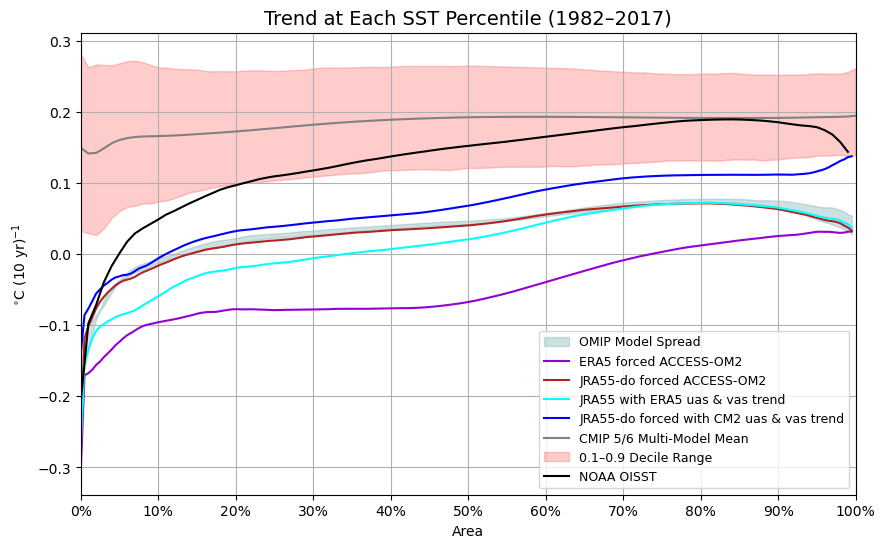

In [12]:
fig, axes = plt.subplots(figsize=(10, 6))

# -------------------------
# OMIP SHADED REGION (exclude last model)
# -------------------------
omip_models = mod_labs[:-1]          # all except last
special_mod = mod_labs[-1]           # last model (plot separately)

# Stack all OMIP models
omip_stack = xr.concat(
    [percentiles_omip_trend[m] for m in omip_models],
    dim='model'
) * 12 * 10

# Ensemble stats
omip_min  = omip_stack.min(dim='model')
omip_max  = omip_stack.max(dim='model')
omip_mean = omip_stack.mean(dim='model')

# Shaded region
axes.fill_between(
    omip_stack.area,
    omip_min,
    omip_max,
    color='cadetblue',
    alpha=0.3,
    label='OMIP Model Spread'
)

# # Optional OMIP mean line
# axes.plot(
#     omip_stack.area,
#     omip_mean,
#     color='orange',
#     lw=2,
#     label='OMIP Mean'
# )

# -------------------------
# SPECIAL MODEL (last entry)
# -------------------------
(era5_percent_trend * 12 * 10).plot(
    ax=axes,
    color='darkviolet',
    label='ERA5 forced ACCESS-OM2',
    lw=1.5
)

# -------------------------
# ACCESS-OM2 runs
# -------------------------
(control_percent_trend*12*10).plot(ax=axes, label='JRA55-do forced ACCESS-OM2', color='firebrick',lw=1.5)
# (perturb_percent_era5_uas_trend*12*10).plot(ax=axes, label='JRA55 with ERA5 uas trend', color='cyan')
(perturb_percent_era5_uas_vas_trend*12*10).plot(ax=axes, label='JRA55 with ERA5 uas & vas trend', color='cyan')
# (perturb_percent_era5_rsds_rlds_trend*12*10).plot(ax=axes, label='JRA55 with ERA5 rsds & rlds trend', color='indianred')
# ((perturb_percent_era5_huss_tas_trend)*12*10).plot(ax=axes, label='JRA55 with ERA5 huss & tas trend', color='limegreen')
# ((perturb_percent_era5_winds)*12*10).plot(ax=axes, label='JRA55 with ERA5 winds trend', color='violet')
# ((perturb_percent_all_trend)*12*10).plot(ax=axes, label='JRA55 with ERA5 all-ish trends', color='orange',lw = 1.5)
(perturb_percent_cm2_winds_trend*12*10).plot(ax=axes, label='JRA55-do forced with CM2 uas & vas trend', color='blue',lw = 1.5)

# (cm2_percent_trend*10*12).plot(ax=axes, label='ACCESS-CM2', color='red')
# -------------------------
# CMIP + envelope
# -------------------------
sns.lineplot(x="area", y="mean", data=df, ax=axes, color='grey', label='CMIP 5/6 Multi-Model Mean')
axes.fill_between(df['area'], df['upper'], df['lower'], alpha=0.2, color='red',
                  label='0.1–0.9 Decile Range')

# NOAA observational line
axes.plot(noaa_sst_trend.area.values, noaa_sst_trend.values * 10 * 12,
          color='k', label='NOAA OISST')

# -------------------------
# Formatting
# -------------------------
axes.set_xticks(np.linspace(0, 1, 11))
axes.set_xticklabels([f'{int(x*100)}%' for x in np.linspace(0, 1, 11)])
axes.grid(True)
axes.legend(loc='lower right', fontsize=9)
axes.set_xlim(0, 1)
axes.set_ylabel(r'$^{\circ}$C (10 yr)$^{-1}$')
axes.set_xlabel('Area')
plt.title('Trend at Each SST Percentile (1982–2017)', fontsize=14)


Text(0.5, 1.0, 'Trend at Each SST Percentile (1982–2017)')

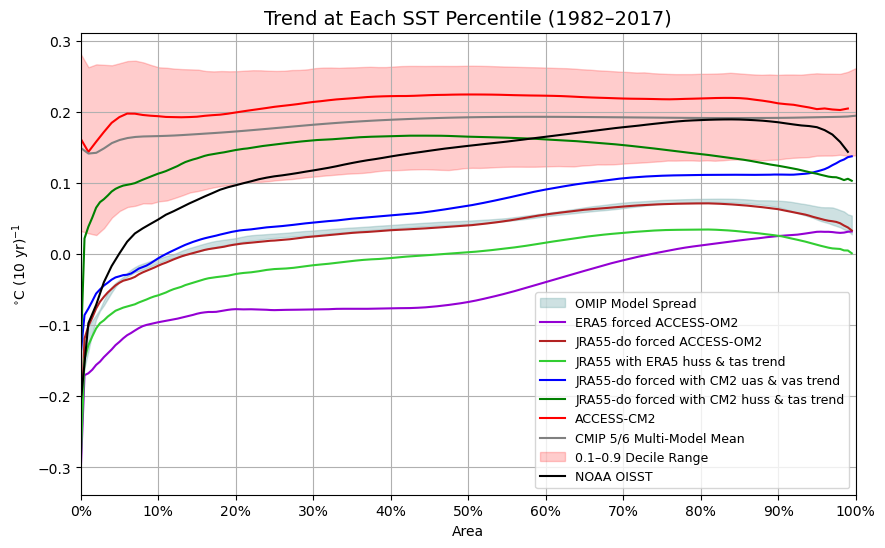

In [9]:
fig, axes = plt.subplots(figsize=(10, 6))

# -------------------------
# OMIP SHADED REGION (exclude last model)
# -------------------------
omip_models = mod_labs[:-1]          # all except last
special_mod = mod_labs[-1]           # last model (plot separately)

# Stack all OMIP models
omip_stack = xr.concat(
    [percentiles_omip_trend[m] for m in omip_models],
    dim='model'
) * 12 * 10

# Ensemble stats
omip_min  = omip_stack.min(dim='model')
omip_max  = omip_stack.max(dim='model')
omip_mean = omip_stack.mean(dim='model')

# Shaded region
axes.fill_between(
    omip_stack.area,
    omip_min,
    omip_max,
    color='cadetblue',
    alpha=0.3,
    label='OMIP Model Spread'
)

# # Optional OMIP mean line
# axes.plot(
#     omip_stack.area,
#     omip_mean,
#     color='orange',
#     lw=2,
#     label='OMIP Mean'
# )

# -------------------------
# SPECIAL MODEL (last entry)
# -------------------------
(era5_percent_trend * 12 * 10).plot(
    ax=axes,
    color='darkviolet',
    label='ERA5 forced ACCESS-OM2',
    lw=1.5
)

# -------------------------
# ACCESS-OM2 runs
# -------------------------
(control_percent_trend*12*10).plot(ax=axes, label='JRA55-do forced ACCESS-OM2', color='firebrick',lw=1.5)
# (perturb_percent_era5_uas_trend*12*10).plot(ax=axes, label='JRA55 with ERA5 uas trend', color='cyan')
# (perturb_percent_era5_uas_vas_trend*12*10).plot(ax=axes, label='JRA55 with ERA5 uas & vas trend', color='cyan')
# (perturb_percent_era5_rsds_rlds_trend*12*10).plot(ax=axes, label='JRA55 with ERA5 rsds & rlds trend', color='indianred',lw=1)
((perturb_percent_era5_huss_tas_trend)*12*10).plot(ax=axes, label='JRA55 with ERA5 huss & tas trend', color='limegreen')
# ((perturb_percent_era5_winds)*12*10).plot(ax=axes, label='JRA55 with ERA5 winds trend', color='violet')
# ((perturb_percent_all_trend)*12*10).plot(ax=axes, label='JRA55 with ERA5 all-ish trends', color='orange',lw = 1.5)
(perturb_percent_cm2_winds_trend*12*10).plot(ax=axes, label='JRA55-do forced with CM2 uas & vas trend', color='blue',lw = 1.5)
(perturb_percent_cm2_huss_tas_trend*12*10).plot(ax=axes, label='JRA55-do forced with CM2 huss & tas trend', color='green',lw = 1.5)
(cm2_percent_trend*10*12).plot(ax=axes, label='ACCESS-CM2', color='red')
# -------------------------
# CMIP + envelope
# -------------------------
sns.lineplot(x="area", y="mean", data=df, ax=axes, color='grey', label='CMIP 5/6 Multi-Model Mean')
axes.fill_between(df['area'], df['upper'], df['lower'], alpha=0.2, color='red',
                  label='0.1–0.9 Decile Range')

# NOAA observational line
axes.plot(noaa_sst_trend.area.values, noaa_sst_trend.values * 10 * 12,
          color='k', label='NOAA OISST')

# -------------------------
# Formatting
# -------------------------
axes.set_xticks(np.linspace(0, 1, 11))
axes.set_xticklabels([f'{int(x*100)}%' for x in np.linspace(0, 1, 11)])
axes.grid(True)
axes.legend(loc='lower right', fontsize=9)
axes.set_xlim(0, 1)
axes.set_ylabel(r'$^{\circ}$C (10 yr)$^{-1}$')
axes.set_xlabel('Area')
plt.title('Trend at Each SST Percentile (1982–2017)', fontsize=14)


# difference 

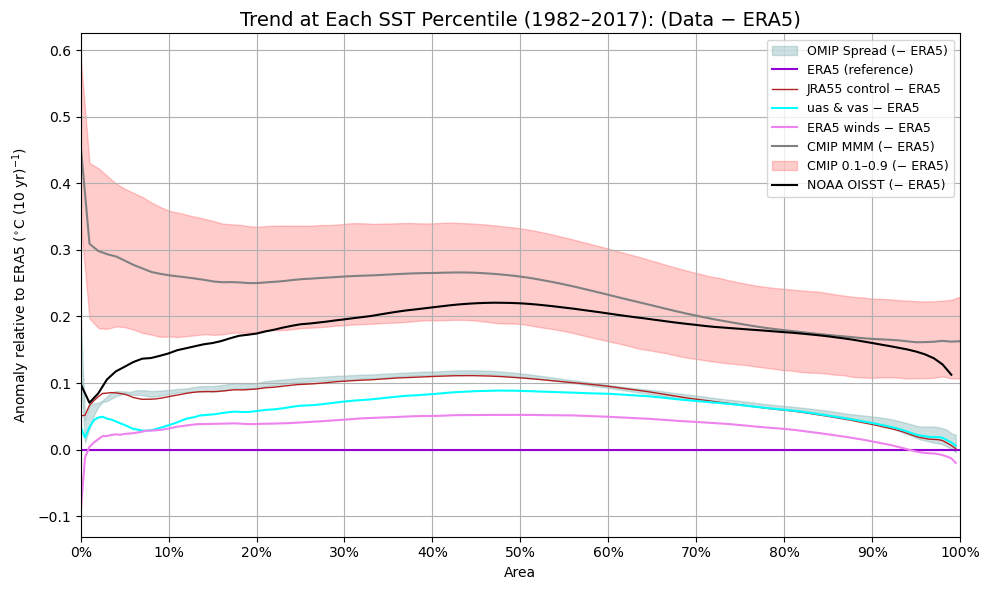

In [10]:
fig, axes = plt.subplots(figsize=(10, 6))

# Reference (ERA5) in °C/10yr
ref = era5_percent_trend
ref10 = ref * 12 * 10

# -------------------------
# OMIP SHADED REGION (relative to ERA5)
# -------------------------
omip_models = mod_labs[:-1]
special_mod = mod_labs[-1]  # unused now, but kept

omip_stack = xr.concat([percentiles_omip_trend[m] for m in omip_models], dim="model")
omip_stack_diff = (omip_stack - ref) * 12 * 10

omip_min  = omip_stack_diff.min(dim="model")
omip_max  = omip_stack_diff.max(dim="model")
omip_mean = omip_stack_diff.mean(dim="model")

axes.fill_between(
    omip_stack_diff.area,
    omip_min,
    omip_max,
    color="cadetblue",
    alpha=0.3,
    label="OMIP Spread (− ERA5)"
)

# optional: OMIP mean (relative)
# axes.plot(omip_stack_diff.area, omip_mean, color="orange", lw=2, label="OMIP Mean (− ERA5)")

# -------------------------
# ERA5 reference line at zero
# -------------------------
axes.axhline(0, color="darkviolet", lw=1.5, label="ERA5 (reference)")

# -------------------------
# ACCESS-OM2 runs (relative to ERA5)
# -------------------------
((control_percent_trend - ref) * 12 * 10).plot(ax=axes, label="JRA55 control − ERA5", color="firebrick", lw=1)
((perturb_percent_era5_uas_vas_trend - ref) * 12 * 10).plot(ax=axes, label="uas & vas − ERA5", color="cyan")
# ((perturb_percent_era5_rsds_rlds_trend - ref) * 12 * 10).plot(ax=axes, label="rsds & rlds − ERA5", color="orangered", lw=1)
# ((perturb_percent_era5_huss_tas_trend - ref) * 12 * 10).plot(ax=axes, label="huss & tas − ERA5", color="limegreen")
((perturb_percent_era5_winds - ref) * 12 * 10).plot(ax=axes, label="ERA5 winds − ERA5", color="violet")
# ((perturb_percent_all_trend - ref) * 12 * 10).plot(ax=axes, label="all-ish − ERA5", color="orange", lw=1.5)

# -------------------------
# CMIP mean + envelope (relative to ERA5)
# df columns assumed already in °C/10yr on x="area"
# -------------------------
ref_on_df = np.interp(df["area"].values, ref10.area.values, ref10.values)

df_rel = df.copy()
df_rel["mean"]  = df_rel["mean"]  - ref_on_df
df_rel["upper"] = df_rel["upper"] - ref_on_df
df_rel["lower"] = df_rel["lower"] - ref_on_df

sns.lineplot(x="area", y="mean", data=df_rel, ax=axes, color="grey", label="CMIP MMM (− ERA5)")
axes.fill_between(df_rel["area"], df_rel["upper"], df_rel["lower"], alpha=0.2, color="red",
                  label="CMIP 0.1–0.9 (− ERA5)")

# -------------------------
# NOAA observational line (relative to ERA5)
# -------------------------
noaa10 = noaa_sst_trend * 10 * 12
(noaa10 - ref10).plot(ax=axes, color="k", label="NOAA OISST (− ERA5)")

# -------------------------
# Formatting
# -------------------------
axes.set_xticks(np.linspace(0, 1, 11))
axes.set_xticklabels([f"{int(x*100)}%" for x in np.linspace(0, 1, 11)])
axes.grid(True)
axes.legend(loc="upper right", fontsize=9)
axes.set_xlim(0, 1)
axes.set_ylabel(r"Anomaly relative to ERA5 ($^{\circ}$C (10 yr)$^{-1}$)")
axes.set_xlabel("Area")
plt.title("Trend at Each SST Percentile (1982–2017): (Data − ERA5)", fontsize=14)
plt.tight_layout()


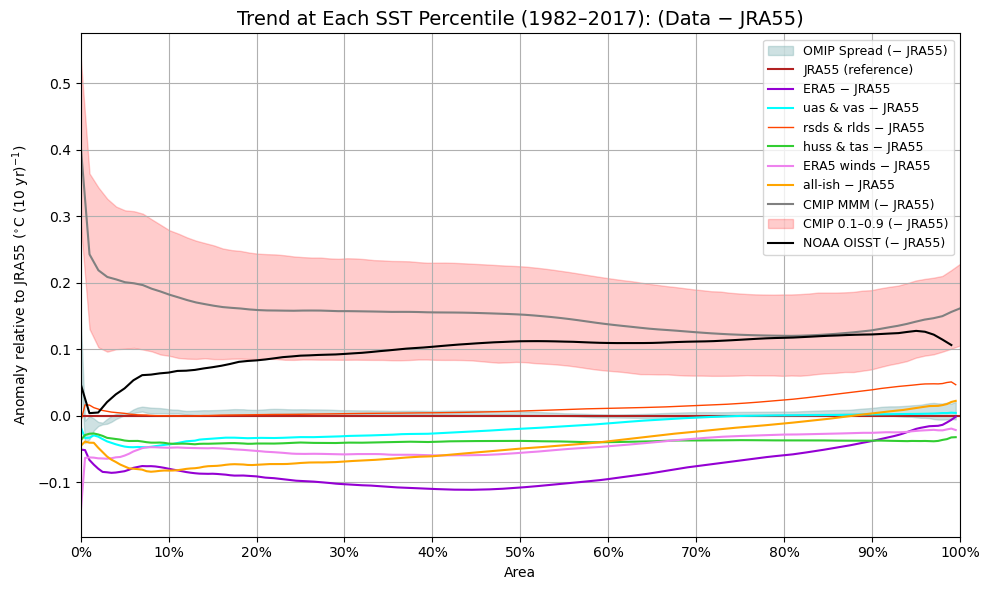

In [11]:
fig, axes = plt.subplots(figsize=(10, 6))

# Reference (JRA55 control) in °C/10yr
ref = control_percent_trend
ref10 = ref * 12 * 10

# -------------------------
# OMIP SHADED REGION (relative to JRA55)
# -------------------------
omip_models = mod_labs[:-1]

omip_stack = xr.concat([percentiles_omip_trend[m] for m in omip_models], dim="model")
omip_stack_diff = (omip_stack - ref) * 12 * 10

omip_min  = omip_stack_diff.min(dim="model")
omip_max  = omip_stack_diff.max(dim="model")
omip_mean = omip_stack_diff.mean(dim="model")

axes.fill_between(
    omip_stack_diff.area,
    omip_min,
    omip_max,
    color="cadetblue",
    alpha=0.3,
    label="OMIP Spread (− JRA55)"
)

# -------------------------
# JRA55 reference line at zero
# -------------------------
axes.axhline(0, color="firebrick", lw=1.5, label="JRA55 (reference)")

# -------------------------
# Other lines (relative to JRA55)
# -------------------------
((era5_percent_trend - ref) * 12 * 10).plot(ax=axes, label="ERA5 − JRA55", color="darkviolet", lw=1.5)
((perturb_percent_era5_uas_vas_trend - ref) * 12 * 10).plot(ax=axes, label="uas & vas − JRA55", color="cyan")
((perturb_percent_era5_rsds_rlds_trend - ref) * 12 * 10).plot(ax=axes, label="rsds & rlds − JRA55", color="orangered", lw=1)
((perturb_percent_era5_huss_tas_trend - ref) * 12 * 10).plot(ax=axes, label="huss & tas − JRA55", color="limegreen")
((perturb_percent_era5_winds - ref) * 12 * 10).plot(ax=axes, label="ERA5 winds − JRA55", color="violet")
((perturb_percent_all_trend - ref) * 12 * 10).plot(ax=axes, label="all-ish − JRA55", color="orange", lw=1.5)

# -------------------------
# CMIP mean + envelope (relative to JRA55)
# df columns assumed already in °C/10yr on x="area"
# -------------------------
ref_on_df = np.interp(df["area"].values, ref10.area.values, ref10.values)

df_rel = df.copy()
df_rel["mean"]  = df_rel["mean"]  - ref_on_df
df_rel["upper"] = df_rel["upper"] - ref_on_df
df_rel["lower"] = df_rel["lower"] - ref_on_df

sns.lineplot(x="area", y="mean", data=df_rel, ax=axes, color="grey", label="CMIP MMM (− JRA55)")
axes.fill_between(df_rel["area"], df_rel["upper"], df_rel["lower"], alpha=0.2, color="red",
                  label="CMIP 0.1–0.9 (− JRA55)")

# -------------------------
# NOAA observational line (relative to JRA55)
# -------------------------
noaa10 = noaa_sst_trend * 10 * 12
(noaa10 - ref10).plot(ax=axes, color="k", label="NOAA OISST (− JRA55)")

# -------------------------
# Formatting
# -------------------------
axes.set_xticks(np.linspace(0, 1, 11))
axes.set_xticklabels([f"{int(x*100)}%" for x in np.linspace(0, 1, 11)])
axes.grid(True)
axes.legend(loc="upper right", fontsize=9)
axes.set_xlim(0, 1)
axes.set_ylabel(r"Anomaly relative to JRA55 ($^{\circ}$C (10 yr)$^{-1}$)")
axes.set_xlabel("Area")
plt.title("Trend at Each SST Percentile (1982–2017): (Data − JRA55)", fontsize=14)
plt.tight_layout()


In [ ]:
# Save this notebook's variables so later (plotting) notebooks can load them.
save_state(globals())
